# 4. Xây mô hình và đánh giá

Notebook 1 đến 3 đã biến dữ liệu bẩn thành `credit_clean.csv` và `credit_features.csv`. Notebook này trả lời ba câu hỏi:

1. Làm sạch giúp mô hình được bao nhiêu? Đây là câu hỏi chính của bài, trả lời bằng thí nghiệm ablation (bỏ hoặc thêm từng bước làm sạch rồi so sánh).
2. Mô hình nào tốt nhất, chỉnh siêu tham số và xử lý lệch lớp thế nào?
3. Kết quả cuối trên tập kiểm tra chưa từng dùng, mô hình dựa vào đặc trưng nào, và sai ở đâu?

## Cách đánh giá
Có vài chỗ rất dễ làm kết quả đẹp giả, nên cách làm được chọn trước như sau:

| Vấn đề | Cách xử lý |
|---|---|
| Mỗi khách có 8 dòng gần giống nhau. Nếu chia ngẫu nhiên theo dòng thì cùng một người nằm ở cả train và test, mô hình chỉ cần nhớ người đó | Chia theo khách: `GroupShuffleSplit` để tách tập kiểm tra, `StratifiedGroupKFold` cho cross-validation (CV) |
| Nhãn lệch lớp (Standard 53%, Good 18%) nên accuracy dễ đánh lừa | Chỉ số chính là macro-F1 (trung bình F1 của ba lớp). Báo thêm accuracy và recall từng lớp |
| Nếu chọn mô hình hay siêu tham số bằng cách nhìn tập kiểm tra thì kết quả bị lạc quan | Tập kiểm tra (20% số khách) chỉ dùng một lần ở cuối. Mọi lựa chọn dùng CV trên 80% còn lại |
| Một lần chạy có thể do may rủi | CV 5 phần, báo trung bình ± độ lệch chuẩn giữa các phần. Kết quả cuối có khoảng tin cậy bootstrap theo khách |
| Cần một mốc để so | Luôn đoán lớp phổ biến nhất (Standard) cho accuracy khoảng 53% |

In [1]:
import os
import re
import sys
import json
import time
import warnings
sys.path.insert(0, '../src')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import Markdown, display
from scipy.stats import loguniform, randint
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.inspection import PartialDependenceDisplay, permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, classification_report, confusion_matrix, f1_score, log_loss,
                             precision_recall_fscore_support, roc_auc_score)
from sklearn.model_selection import GroupShuffleSplit, RandomizedSearchCV, StratifiedGroupKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier

import credit_cleaning as cc
import credit_features as cf
from notebook_utils import LABELS, COLORS, setup_style

warnings.filterwarnings('ignore')
setup_style()
os.makedirs('../data/reports', exist_ok=True)
start_time = time.time()


def say(text):
    """Hiện một đoạn markdown, đổi số thập phân sang dấu phẩy cho giống phần chữ (giữ nguyên số mục như 'mục 4.2' và số khách như '2.500 khách')."""
    text = re.sub(r'mục (\d+)\.(\d+)', r'mục \1§\2', text)
    text = re.sub(r'(\d+)\.(\d{3}) khách', r'\1§\2 khách', text)          # giữ "2.500 khách" (dấu chấm ngăn cách hàng nghìn)
    text = re.sub(r'(?<=\d)\.(?=\d)', ',', text)
    display(Markdown(text.replace('§', '.')))


raw = pd.read_csv('../data/train.csv', low_memory=False)
clean = pd.read_csv('../data/credit_clean.csv')
feat = pd.read_csv('../data/credit_features.csv')

assert len(raw) == len(clean) == len(feat)
assert (raw.ID.values == clean.ID.values).all() and (clean.ID.values == feat.ID.values).all()

y_all = clean['Credit_Score']
customer_all = clean['Customer_ID']
print('dữ liệu thô', raw.shape, '| dữ liệu sạch', clean.shape, '| đặc trưng', feat.shape)

dữ liệu thô (100000, 28) | dữ liệu sạch (100000, 29) | đặc trưng (100000, 74)


## 4.1 Chia dữ liệu theo khách hàng
Lấy ngẫu nhiên 20% số khách (2.500 người, đủ 8 tháng của mỗi người) làm tập kiểm tra giữ kín. 80% còn lại (10.000 khách) dùng cho mọi thí nghiệm bằng CV 5 phần.

In [2]:
splitter = GroupShuffleSplit(n_splits=1, test_size=0.20, random_state=42)
train_idx, test_idx = next(splitter.split(clean, y_all, customer_all))

y_train = y_all.iloc[train_idx].reset_index(drop=True)
y_test = y_all.iloc[test_idx].reset_index(drop=True)
cust_train = customer_all.iloc[train_idx].reset_index(drop=True)
cust_test = customer_all.iloc[test_idx].reset_index(drop=True)
assert set(cust_train).isdisjoint(set(cust_test))

cv5 = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)
folds = list(cv5.split(np.zeros(len(y_train)), y_train, cust_train))

print(f'Train: {len(train_idx):,} dòng, {cust_train.nunique():,} khách | '
      f'Test giữ kín: {len(test_idx):,} dòng, {cust_test.nunique():,} khách | không trùng khách')
print(pd.DataFrame({'train': y_train.value_counts(normalize=True),
                    'test': y_test.value_counts(normalize=True)}).reindex(LABELS).round(3).T.to_string())
print('Mốc so sánh (luôn đoán Standard): accuracy trên test =', round((y_test == 'Standard').mean(), 3))

Train: 80,000 dòng, 10,000 khách | Test giữ kín: 20,000 dòng, 2,500 khách | không trùng khách
Credit_Score   Poor  Standard   Good
train         0.291     0.532  0.177
test          0.286     0.529  0.185
Mốc so sánh (luôn đoán Standard): accuracy trên test = 0.529


In [3]:
def cv_scores(make_model, X):
    """Chạy CV 5 phần theo khách trên tập train. Trả về mảng (5 phần x 2 cột): accuracy và macro-F1 của từng phần."""
    scores = []
    for fit_rows, val_rows in folds:
        model = make_model().fit(X.iloc[fit_rows], y_train.iloc[fit_rows])
        pred = model.predict(X.iloc[val_rows])
        scores.append((accuracy_score(y_train.iloc[val_rows], pred),
                       f1_score(y_train.iloc[val_rows], pred, average='macro')))
    return np.array(scores)


def mean_sd(values):
    """Chuỗi 'trung bình ± độ lệch chuẩn' để đưa vào bảng."""
    return f'{values.mean():.3f} ± {values.std():.3f}'


MODELS = {
    'Logistic Regression':  lambda: make_pipeline(StandardScaler(), LogisticRegression(max_iter=3000)),
    'Random Forest':        lambda: RandomForestClassifier(n_estimators=150, min_samples_leaf=2, n_jobs=2, random_state=0),
    'HistGradientBoosting': lambda: HistGradientBoostingClassifier(max_iter=200, random_state=0),
}

## 4.2 Thí nghiệm chính: làm sạch giúp được bao nhiêu? (ablation)

Dùng cùng một bộ cột gốc (`BASE`: 17 cột số và 4 cột chữ), cùng mô hình, cùng 5 phần CV. Chỉ thay đổi mức độ làm sạch, cộng dần từng bước của pipeline:

| Giai đoạn | Nội dung | Giống ai |
|---|---|---|
| S0, dữ liệu thô | Chỉ bỏ dấu `_` và ép kiểu số. Giá trị giả còn nguyên (`__10000__` thành 10000, `-3·10²⁶`, `Credit_Mix = '_'`). Ô thiếu điền trung vị hoặc giá trị phổ biến của cả cột | Người tải về rồi chạy luôn |
| S1, bỏ giá trị giả | S0, nhưng giá trị giả đổi thành NaN trước, rồi điền như trên | |
| S2, bỏ giá trị vô lý | S1, thêm việc loại các giá trị ngoài miền hợp lệ, rồi điền như trên | |
| S3, làm sạch đầy đủ | S2, nhưng điền theo từng khách và theo chiến lược đã kiểm chứng ở notebook 2 (chính là `credit_clean.csv`) | Bài này |
| S2* | S2, không điền gì, để HistGradientBoosting tự xử lý NaN | Cách "để mô hình lo" |

Có S2* để trả lời câu hỏi hay gặp: mô hình tự xử lý NaN được rồi, cần gì làm sạch.

In [4]:
def fill_global(d, num_cols, cat_cols):
    """Cách điền đơn giản nhất: cột số điền trung vị cả cột, cột chữ điền giá trị phổ biến nhất."""
    d = d.copy()
    for c in num_cols:
        d[c] = d[c].fillna(d[c].median())
    for c in cat_cols:
        d[c] = d[c].fillna(d[c].mode().iloc[0])
    return d


def basic_matrix(d, fill=True):
    """Ma trận đặc trưng từ các cột gốc (17 cột số, 4 cột chữ được one-hot). fill=True thì điền ô thiếu kiểu fill_global."""
    if fill:
        d = fill_global(d, cf.BASE_NUM, cf.BASE_CAT)
    return pd.get_dummies(d[cf.BASE_NUM + cf.BASE_CAT], columns=cf.BASE_CAT, dtype=float)


def add_history_months(d):
    """Đổi Credit_History_Age ('22 Years and 9 Months') thành số tháng."""
    return d.assign(Credit_History_Months=d['Credit_History_Age'].map(cc.parse_history_months))


start = cc.add_month_num(raw)
s0 = add_history_months(cc.strip_numeric_text(start))                              # S0: chỉ ép kiểu số
s1 = add_history_months(cc.strip_numeric_text(cc.mark_placeholders(start)))        # S1: giá trị giả thành NaN
s2 = cc.mark_invalid(s1.copy())                                                    # S2: giá trị vô lý thành NaN

STAGE_NAMES = ['S0 – Thô', 'S1 – Bỏ placeholder', 'S2 – Bỏ giá trị vô lý', 'S3 – Làm sạch đầy đủ']
STAGE_STAR = 'S2* – Vô lý→NaN, mô hình tự xử lý NaN'

stage_full = {'S0 – Thô': basic_matrix(s0), 'S1 – Bỏ placeholder': basic_matrix(s1),
              'S2 – Bỏ giá trị vô lý': basic_matrix(s2), 'S3 – Làm sạch đầy đủ': basic_matrix(clean)}
X_stage = {name: m.iloc[train_idx].reset_index(drop=True) for name, m in stage_full.items()}
X_star = basic_matrix(s2, fill=False).iloc[train_idx].reset_index(drop=True)       # S2*: giữ NaN

for name, m in X_stage.items():
    print(f'{name:26s} {m.shape}   NaN còn lại: {int(m.isna().sum().sum())}')
print(f'{STAGE_STAR[:3]:26s} {X_star.shape}   NaN còn lại: {int(X_star.isna().sum().sum())} (để mô hình tự xử lý)')

S0 – Thô                   (80000, 47)   NaN còn lại: 0
S1 – Bỏ placeholder        (80000, 44)   NaN còn lại: 0
S2 – Bỏ giá trị vô lý      (80000, 44)   NaN còn lại: 0
S3 – Làm sạch đầy đủ       (80000, 45)   NaN còn lại: 0
S2*                        (80000, 44)   NaN còn lại: 52118 (để mô hình tự xử lý)


In [5]:
# Logistic Regression kém ở S0 vì dữ liệu thô có giá trị cực lớn, làm phép chuẩn hóa mất tác dụng
extreme = s0[cf.BASE_NUM].agg(['min', 'max']).T
order = extreme.abs().max(axis=1).sort_values(ascending=False).index
print(extreme.loc[order].head(5).to_string(float_format=lambda v: f'{v:.3g}'))

                              min      max
Monthly_Balance         -3.33e+26  1.6e+03
Annual_Income            7.01e+03 2.42e+07
Total_EMI_per_month             0 8.23e+04
Monthly_Inhand_Salary         304 1.52e+04
Amount_invested_monthly         0    1e+04


In [6]:
rows = []
for model_name, make_model in MODELS.items():
    for stage, X in X_stage.items():
        t = time.time()
        scores = cv_scores(make_model, X)
        rows.append({'mô hình': model_name, 'giai đoạn': stage,
                     'acc': scores[:, 0].mean(), 'acc_sd': scores[:, 0].std(),
                     'f1': scores[:, 1].mean(), 'f1_sd': scores[:, 1].std(),
                     'f1_folds': scores[:, 1].round(5).tolist()})
        print(f'{model_name:22s} {stage:26s} macro-F1 {scores[:, 1].mean():.4f} ± {scores[:, 1].std():.4f}   ({time.time() - t:.0f}s)', flush=True)

scores = cv_scores(MODELS['HistGradientBoosting'], X_star)
rows.append({'mô hình': 'HistGradientBoosting', 'giai đoạn': STAGE_STAR,
             'acc': scores[:, 0].mean(), 'acc_sd': scores[:, 0].std(),
             'f1': scores[:, 1].mean(), 'f1_sd': scores[:, 1].std(),
             'f1_folds': scores[:, 1].round(5).tolist()})
print(f'HistGradientBoosting tự xử lý NaN (S2*): macro-F1 {scores[:, 1].mean():.4f} ± {scores[:, 1].std():.4f}')

ablation = pd.DataFrame(rows)
ablation.to_csv('../data/reports/ablation_cleaning.csv', index=False)

Logistic Regression    S0 – Thô                   macro-F1 0.5888 ± 0.0054   (4s)


Logistic Regression    S1 – Bỏ placeholder        macro-F1 0.5846 ± 0.0065   (4s)


Logistic Regression    S2 – Bỏ giá trị vô lý      macro-F1 0.6116 ± 0.0057   (8s)


Logistic Regression    S3 – Làm sạch đầy đủ       macro-F1 0.6393 ± 0.0065   (16s)


Random Forest          S0 – Thô                   macro-F1 0.6690 ± 0.0018   (60s)


...

HistGradientBoosting   S0 – Thô                   macro-F1 0.6621 ± 0.0052   (37s)


HistGradientBoosting   S1 – Bỏ placeholder        macro-F1 0.6599 ± 0.0045   (36s)


HistGradientBoosting   S2 – Bỏ giá trị vô lý      macro-F1 0.6572 ± 0.0017   (36s)


HistGradientBoosting   S3 – Làm sạch đầy đủ       macro-F1 0.6712 ± 0.0035   (35s)


HistGradientBoosting tự xử lý NaN (S2*): macro-F1 0.6634 ± 0.0040


mô hình,HistGradientBoosting,Logistic Regression,Random Forest
giai đoạn,,,
S0 – Thô,0.662 ± 0.005,0.589 ± 0.005,0.669 ± 0.002
S1 – Bỏ placeholder,0.660 ± 0.005,0.585 ± 0.006,0.667 ± 0.004
S2 – Bỏ giá trị vô lý,0.657 ± 0.002,0.612 ± 0.006,0.667 ± 0.002
"S2* – Vô lý→NaN, mô hình tự xử lý NaN",0.663 ± 0.004,NaN,NaN
S3 – Làm sạch đầy đủ,0.671 ± 0.004,0.639 ± 0.006,0.679 ± 0.001


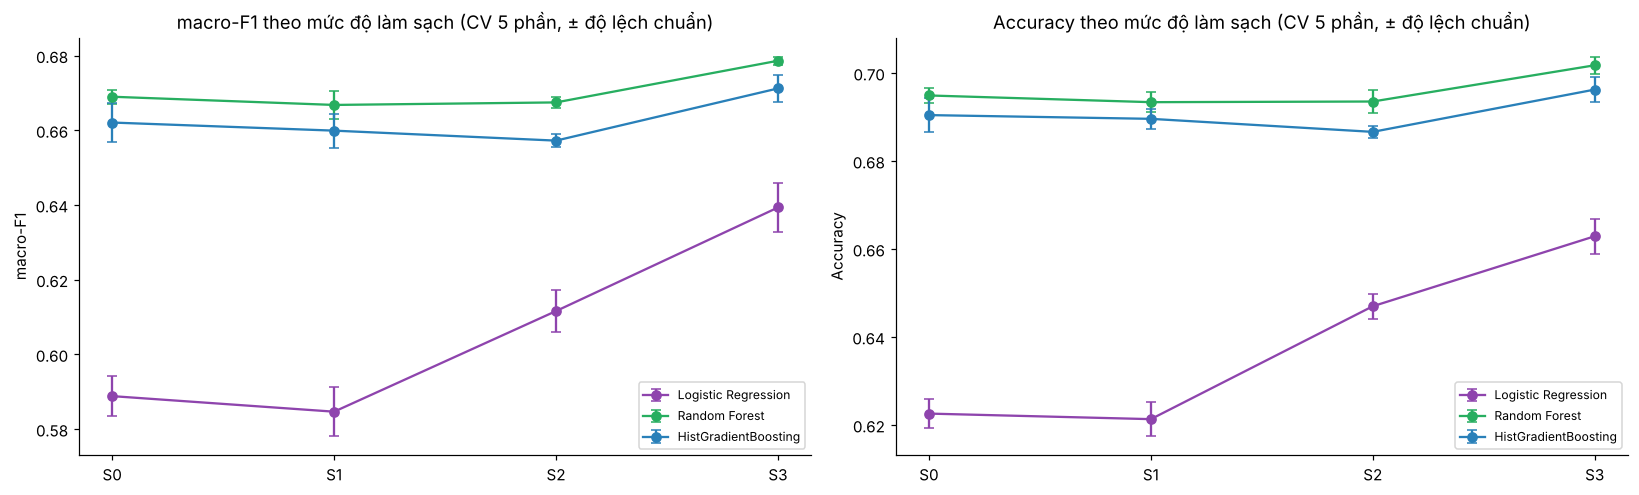

In [7]:
ablation['macro-F1'] = ablation.f1.map('{:.3f}'.format) + ' ± ' + ablation.f1_sd.map('{:.3f}'.format)
display(ablation.pivot(index='giai đoạn', columns='mô hình', values='macro-F1'))

MODEL_COLORS = {'Logistic Regression': '#8e44ad', 'Random Forest': '#27ae60', 'HistGradientBoosting': '#2980b9'}
fig, ax = plt.subplots(1, 2, figsize=(15, 4.6))
for a, (metric, sd, title) in zip(ax, [('f1', 'f1_sd', 'macro-F1'), ('acc', 'acc_sd', 'Accuracy')]):
    for model_name, color in MODEL_COLORS.items():
        s = ablation[(ablation['mô hình'] == model_name) & ablation['giai đoạn'].isin(STAGE_NAMES)]
        s = s.set_index('giai đoạn').loc[STAGE_NAMES]
        a.errorbar(range(4), s[metric], yerr=s[sd], marker='o', color=color, label=model_name, capsize=3)
    a.set_xticks(range(4))
    a.set_xticklabels([x.split(' – ')[0] for x in STAGE_NAMES])
    a.set_ylabel(title)
    a.set_title(f'{title} theo mức độ làm sạch (CV 5 phần, ± độ lệch chuẩn)')
    a.legend(fontsize=8)
plt.tight_layout()
plt.show()

In [8]:
by_stage = ablation.set_index(['mô hình', 'giai đoạn'])
HGB = 'HistGradientBoosting'
TREES = ['Random Forest', HGB]

def fold_f1(model_name, stage):
    return np.array(by_stage.loc[(model_name, stage), 'f1_folds'])

rows = []
for model_name in MODEL_COLORS:
    pairs = [(STAGE_NAMES[3], STAGE_NAMES[0]), (STAGE_NAMES[3], STAGE_NAMES[2])]
    if model_name == HGB:
        pairs.append((STAGE_NAMES[3], STAGE_STAR))
    for better, worse in pairs:
        diff = fold_f1(model_name, better) - fold_f1(model_name, worse)
        rows.append({'mô hình': model_name, 'so sánh': better.split(' – ')[0] + ' − ' + worse.split(' – ')[0],
                     'Δ macro-F1 TB (điểm %)': diff.mean() * 100,
                     'Δ nhỏ nhất (điểm %)': diff.min() * 100,
                     'số phần cải thiện': f'{int((diff > 0).sum())}/{len(diff)}'})
paired = pd.DataFrame(rows).set_index(['mô hình', 'so sánh'])
paired.round(2)

Δ macro-F1 TB (điểm %)  Δ nhỏ nhất (điểm %) số phần cải thiện
mô hình              so sánh                                                                
Logistic Regression  S3 − S0                     5.05                 4.22               5/5
                     S3 − S2                     2.77                 2.48               5/5
Random Forest        S3 − S0                     0.96                 0.75               5/5
                     S3 − S2                     1.12                 0.91               5/5
HistGradientBoosting S3 − S0                     0.91                 0.06               5/5
                     S3 − S2                     1.40                 1.02               5/5
                     S3 − S2*                    0.78                 0.33               5/5

In [9]:
gain = {m: paired.loc[(m, 'S3 − S0'), 'Δ macro-F1 TB (điểm %)'] for m in MODEL_COLORS}
all_folds_better = all(paired.loc[(m, 'S3 − S0'), 'số phần cải thiện'].split('/')[0] ==
                       paired.loc[(m, 'S3 − S0'), 'số phần cải thiện'].split('/')[1] for m in TREES)
consistency = 'cao hơn S0 ở cả 5 phần CV' if all_folds_better else 'không cao hơn S0 ở mọi phần CV (xem cột "số phần cải thiện")'

def middle_vs_s0(model_name):
    """Chênh lệch macro-F1 (điểm %) của S1 và S2 so với S0."""
    f1_s0 = by_stage.loc[(model_name, STAGE_NAMES[0]), 'f1']
    return [(by_stage.loc[(model_name, s), 'f1'] - f1_s0) * 100 for s in STAGE_NAMES[1:3]]

mid_rf, mid_hgb = middle_vs_s0('Random Forest'), middle_vs_s0(HGB)
star_vs_s0 = (by_stage.loc[(HGB, STAGE_STAR), 'f1'] - by_stage.loc[(HGB, STAGE_NAMES[0]), 'f1']) * 100
star_gap = paired.loc[(HGB, 'S3 − S2*'), 'Δ macro-F1 TB (điểm %)']

say(f"""**Đọc kết quả**

- S3 (làm sạch đầy đủ) có macro-F1 cao nhất ở cả ba mô hình. So với dữ liệu thô, mức tăng là {gain['Logistic Regression']:+.1f} điểm % ở Logistic Regression, {gain['Random Forest']:+.1f} ở Random Forest và {gain[HGB]:+.1f} ở HistGradientBoosting. Ở hai mô hình cây, S3 {consistency}.
- Logistic Regression được lợi nhiều nhất. Mô hình này nhạy với giá trị cực lớn (xem bảng giá trị cực đoan ở trên), nên ở S0 nó kém hẳn hai mô hình cây. Mô hình cây chỉ dựa vào thứ tự của giá trị nên ít bị ảnh hưởng hơn, vì vậy khoảng cách nhỏ hơn.
- Làm sạch kiểu máy móc không đủ. Ở mô hình cây, S1 và S2 so với S0 chênh {mid_rf[0]:+.1f} và {mid_rf[1]:+.1f} điểm % (Random Forest), {mid_hgb[0]:+.1f} và {mid_hgb[1]:+.1f} điểm % (HistGradientBoosting), tức là không hơn dữ liệu thô. Một cách giải thích hợp lý là điền chung một con số cho hàng nghìn ô thiếu cũng làm méo dữ liệu gần ngang với việc giữ giá trị rác (mình chưa kiểm tra riêng điều này). Chỉ khi điền theo từng khách và theo ràng buộc giữa các cột (S3) mới thấy lợi ích.
- Để mô hình tự xử lý NaN (S2*) cũng không giúp: {star_vs_s0:+.1f} điểm % so với S0, và S3 vẫn hơn S2* {star_gap:+.1f} điểm %. Lý do có thể là mô hình không biết ô thiếu của khách này suy ra được từ các tháng khác của chính khách đó.

**Giới hạn:** dù dữ liệu đã sạch, mô hình cây chỉ đạt macro-F1 khoảng 0,67 đến 0,68. Phần làm sạch đóng góp thêm khoảng 1 điểm % cho mô hình cây và khoảng 5 điểm % cho mô hình tuyến tính. Đừng kỳ vọng làm sạch biến mô hình yếu thành mô hình tốt khi bản thân nhãn đã có nhiễu (xem phân tích lỗi ở mục 4.9).""")

**Đọc kết quả**

- S3 (làm sạch đầy đủ) có macro-F1 cao nhất ở cả ba mô hình. So với dữ liệu thô, mức tăng là +5,1 điểm % ở Logistic Regression, +1,0 ở Random Forest và +0,9 ở HistGradientBoosting. Ở hai mô hình cây, S3 cao hơn S0 ở cả 5 phần CV.
- Logistic Regression được lợi nhiều nhất. Mô hình này nhạy với giá trị cực lớn (xem bảng giá trị cực đoan ở trên), nên ở S0 nó kém hẳn hai mô hình cây. Mô hình cây chỉ dựa vào thứ tự của giá trị nên ít bị ảnh hưởng hơn, vì vậy khoảng cách nhỏ hơn.
- Làm sạch kiểu máy móc không đủ. Ở mô hình cây, S1 và S2 so với S0 chênh -0,2 và -0,2 điểm % (Random Forest), -0,2 và -0,5 điểm % (HistGradientBoosting), tức là không hơn dữ liệu thô. Một cách giải thích hợp lý là điền chung một con số cho hàng nghìn ô thiếu cũng làm méo dữ liệu gần ngang với việc giữ giá trị rác (mình chưa kiểm tra riêng điều này). Chỉ khi điền theo từng khách và theo ràng buộc giữa các cột (S3) mới thấy lợi ích.
- Để mô hình tự xử lý NaN (S2*) cũng không giúp: +0,1 điểm % so với S0, và S3 vẫn hơn S2* +0,8 điểm %. Lý do có thể là mô hình không biết ô thiếu của khách này suy ra được từ các tháng khác của chính khách đó.

**Giới hạn:** dù dữ liệu đã sạch, mô hình cây chỉ đạt macro-F1 khoảng 0,67 đến 0,68. Phần làm sạch đóng góp thêm khoảng 1 điểm % cho mô hình cây và khoảng 5 điểm % cho mô hình tuyến tính. Đừng kỳ vọng làm sạch biến mô hình yếu thành mô hình tốt khi bản thân nhãn đã có nhiễu (xem phân tích lỗi ở mục 4.9).

## 4.3 Đặc trưng nào đáng đưa vào? (ablation nhóm đặc trưng)
Trên dữ liệu sạch, thêm dần từng nhóm đặc trưng của notebook 3. Mỗi dòng của bảng là một bộ đặc trưng, cột "Δ so với bộ trước" cho biết nhóm vừa thêm giúp được bao nhiêu.

Hai nhóm cuối khác nhau về bản chất, nên được báo cáo riêng:
- `LAG` chỉ dùng tháng hiện tại và các tháng trước, nên dùng được khi dự đoán thật.
- `CUST_AGG` dùng cả các tháng sau của khách, chỉ hợp lệ khi đã có đủ 8 tháng (đánh giá "nhìn lại").

In [10]:
FEATURE_SETS = {
    'BASE':                                   ['BASE'],
    '+ RATIO':                                ['BASE', 'RATIO'],
    '+ LOAN':                                 ['BASE', 'RATIO', 'LOAN'],
    '+ PB_SPLIT':                             ['BASE', 'RATIO', 'LOAN', 'PB_SPLIT'],
    '+ LAG  (nhân quả – triển khai được)':    ['BASE', 'RATIO', 'LOAN', 'PB_SPLIT', 'LAG'],
    '+ CUST_AGG  (nhìn lại 8 tháng)':         ['BASE', 'RATIO', 'LOAN', 'PB_SPLIT', 'LAG', 'CUST_AGG'],
}

rows = []
for set_name, groups in FEATURE_SETS.items():
    X = cf.make_matrix(feat, groups).iloc[train_idx].reset_index(drop=True)
    for model_name in ['Logistic Regression', HGB]:
        scores = cv_scores(MODELS[model_name], X)
        rows.append({'bộ đặc trưng': set_name, 'số cột': X.shape[1], 'mô hình': model_name,
                     'acc': scores[:, 0].mean(), 'f1': scores[:, 1].mean(), 'f1_sd': scores[:, 1].std()})
        print(f'{set_name:40s} {model_name:22s} số cột={X.shape[1]:3d}  macro-F1 {scores[:, 1].mean():.4f} ± {scores[:, 1].std():.4f}', flush=True)

feature_ablation = pd.DataFrame(rows)
feature_ablation.to_csv('../data/reports/ablation_features.csv', index=False)

table = feature_ablation.pivot(index='bộ đặc trưng', columns='mô hình', values='f1').loc[list(FEATURE_SETS)]
table['số cột'] = feature_ablation.drop_duplicates('bộ đặc trưng').set_index('bộ đặc trưng')['số cột'].loc[list(FEATURE_SETS)]
for model_name in ['Logistic Regression', HGB]:
    table[f'{model_name}: Δ so với bộ trước'] = table[model_name].diff().round(4)
table.round(4)

BASE                                     Logistic Regression    số cột= 45  macro-F1 0.6394 ± 0.0064


BASE                                     HistGradientBoosting   số cột= 45  macro-F1 0.6712 ± 0.0035


+ RATIO                                  Logistic Regression    số cột= 52  macro-F1 0.6394 ± 0.0073


+ RATIO                                  HistGradientBoosting   số cột= 52  macro-F1 0.6710 ± 0.0055


+ LOAN                                   Logistic Regression    số cột= 61  macro-F1 0.6396 ± 0.0076


...

+ LAG  (nhân quả – triển khai được)      Logistic Regression    số cột= 80  macro-F1 0.6432 ± 0.0072


+ LAG  (nhân quả – triển khai được)      HistGradientBoosting   số cột= 80  macro-F1 0.6705 ± 0.0044


+ CUST_AGG  (nhìn lại 8 tháng)           Logistic Regression    số cột= 95  macro-F1 0.6435 ± 0.0065


+ CUST_AGG  (nhìn lại 8 tháng)           HistGradientBoosting   số cột= 95  macro-F1 0.6731 ± 0.0036


mô hình,HistGradientBoosting,Logistic Regression,số cột,Logistic Regression: Δ so với bộ trước,HistGradientBoosting: Δ so với bộ trước
bộ đặc trưng,,,,,
BASE,0.6712,0.6394,45,NaN,NaN
+ RATIO,0.6710,0.6394,52,0.0001,-0.0002
+ LOAN,0.6688,0.6396,61,0.0001,-0.0023
+ PB_SPLIT,0.6708,0.6395,68,-0.0001,0.0020
+ LAG (nhân quả – triển khai được),0.6705,0.6432,80,0.0037,-0.0003
+ CUST_AGG (nhìn lại 8 tháng),0.6731,0.6435,95,0.0003,0.0027


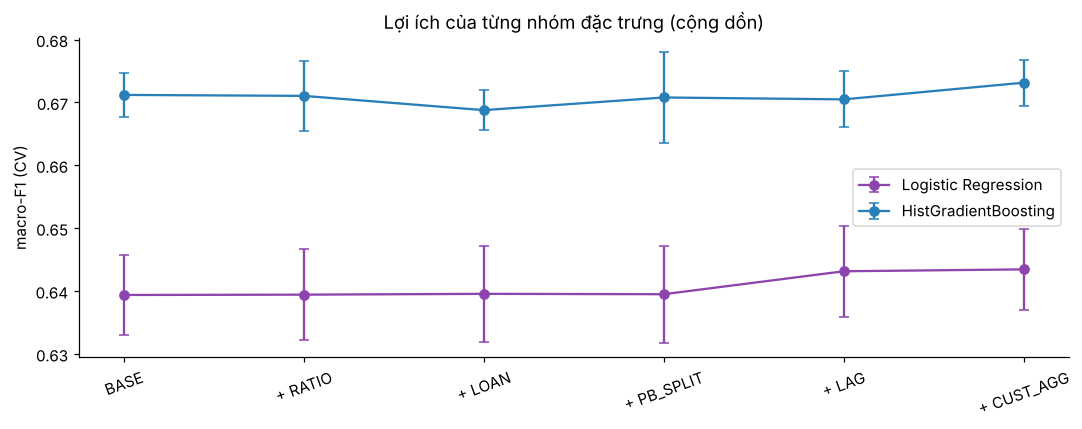

In [11]:
fig, ax = plt.subplots(figsize=(10, 4))
for model_name in ['Logistic Regression', HGB]:
    s = feature_ablation[feature_ablation['mô hình'] == model_name].set_index('bộ đặc trưng').loc[list(FEATURE_SETS)]
    ax.errorbar(range(len(FEATURE_SETS)), s.f1, yerr=s.f1_sd, marker='o', capsize=3, label=model_name,
                color=MODEL_COLORS[model_name])
ax.set_xticks(range(len(FEATURE_SETS)))
ax.set_xticklabels([k.split('  ')[0] for k in FEATURE_SETS], rotation=20)
ax.set_ylabel('macro-F1 (CV)')
ax.set_title('Lợi ích của từng nhóm đặc trưng (cộng dồn)')
ax.legend()
plt.tight_layout()
plt.show()

In [12]:
row_base, row_lag, row_agg = table.loc['BASE'], table.loc['+ LAG  (nhân quả – triển khai được)'], table.loc['+ CUST_AGG  (nhìn lại 8 tháng)']
step = table[[HGB, 'Logistic Regression']].diff().iloc[1:] * 100
sd_max = feature_ablation['f1_sd'].max() * 100
lag_lr = step.loc['+ LAG  (nhân quả – triển khai được)', 'Logistic Regression']

say(f"""**Kết quả (macro-F1, CV).** HistGradientBoosting: BASE {row_base[HGB]:.3f}, thêm đặc trưng nhân quả {row_lag[HGB]:.3f}, thêm cả thống kê 8 tháng {row_agg[HGB]:.3f}. Logistic Regression: {row_base['Logistic Regression']:.3f}, {row_lag['Logistic Regression']:.3f}, {row_agg['Logistic Regression']:.3f}.

Mỗi lần thêm một nhóm, macro-F1 của HistGradientBoosting chỉ đổi trong khoảng {step[HGB].min():+.2f} đến {step[HGB].max():+.2f} điểm %, của Logistic Regression trong khoảng {step['Logistic Regression'].min():+.2f} đến {step['Logistic Regression'].max():+.2f} điểm %. Trong khi đó độ lệch chuẩn giữa các phần CV lên tới {sd_max:.1f} điểm %, nên phần lớn các thay đổi này nằm trong phạm vi nhiễu. Nhóm duy nhất thấy rõ tác dụng là `LAG` với mô hình tuyến tính ({lag_lr:+.2f} điểm %). Các cột gốc đã sạch đã chứa gần hết thông tin, nên tạo đặc trưng chỉ là việc phụ so với làm sạch (mục 4.2).""")

**Kết quả (macro-F1, CV).** HistGradientBoosting: BASE 0,671, thêm đặc trưng nhân quả 0,670, thêm cả thống kê 8 tháng 0,673. Logistic Regression: 0,639, 0,643, 0,643.

Mỗi lần thêm một nhóm, macro-F1 của HistGradientBoosting chỉ đổi trong khoảng -0,23 đến +0,27 điểm %, của Logistic Regression trong khoảng -0,01 đến +0,37 điểm %. Trong khi đó độ lệch chuẩn giữa các phần CV lên tới 0,8 điểm %, nên phần lớn các thay đổi này nằm trong phạm vi nhiễu. Nhóm duy nhất thấy rõ tác dụng là `LAG` với mô hình tuyến tính (+0,37 điểm %). Các cột gốc đã sạch đã chứa gần hết thông tin, nên tạo đặc trưng chỉ là việc phụ so với làm sạch (mục 4.2).

Bộ đặc trưng chính để báo cáo là `BASE + RATIO + LOAN + PB_SPLIT + LAG` (đặc trưng nhân quả). Chọn vậy vì ba lý do, không phải vì nó tốt hơn rõ rệt:
1. Chỉ dùng thông tin đã biết ở thời điểm dự đoán, nên dùng được trong thực tế.
2. Không làm kết quả xấu đi.
3. Giữ lại các đặc trưng có ý nghĩa tài chính để phân tích mức quan trọng ở mục 4.8.

Bộ có thêm `CUST_AGG` (dùng cả các tháng sau) được báo riêng như một mức trần tham khảo ở mục 4.10.

## 4.4 So sánh mô hình trên bộ đặc trưng chính
Cùng bộ đặc trưng, cùng các phần CV. Thêm hai mốc để so: luôn đoán lớp phổ biến, và một cây quyết định đơn giản.

In [13]:
MAIN_GROUPS = ['BASE', 'RATIO', 'LOAN', 'PB_SPLIT', 'LAG']
X_main = cf.make_matrix(feat, MAIN_GROUPS)
X_train = X_main.iloc[train_idx].reset_index(drop=True)
X_test = X_main.iloc[test_idx].reset_index(drop=True)
print('Bộ đặc trưng chính, tập train:', X_train.shape)

CANDIDATES = {'Dummy (lớp phổ biến)': lambda: DummyClassifier(strategy='most_frequent'),
              'Decision Tree (depth 8)': lambda: DecisionTreeClassifier(max_depth=8, random_state=0),
              **MODELS}

rows = []
for model_name, make_model in CANDIDATES.items():
    t = time.time()
    scores = cv_scores(make_model, X_train)
    rows.append({'mô hình': model_name, 'accuracy': mean_sd(scores[:, 0]), 'macro-F1': mean_sd(scores[:, 1]),
                 'f1_mean': scores[:, 1].mean(), 'thời gian (s)': round(time.time() - t)})
comparison = pd.DataFrame(rows).set_index('mô hình')
comparison.to_csv('../data/reports/model_comparison.csv')
comparison.drop(columns='f1_mean')

Bộ đặc trưng chính, tập train: (80000, 80)


,accuracy,macro-F1,thời gian (s)
mô hình,,,
Dummy (lớp phổ biến),0.532 ± 0.000,0.232 ± 0.000,0
Decision Tree (depth 8),0.700 ± 0.007,0.679 ± 0.009,7
Logistic Regression,0.667 ± 0.005,0.643 ± 0.007,32
Random Forest,0.701 ± 0.004,0.679 ± 0.003,87
HistGradientBoosting,0.696 ± 0.004,0.670 ± 0.004,57


## 4.5 Chỉnh siêu tham số
Hai mô hình cây mạnh nhất được chỉnh bằng tìm kiếm ngẫu nhiên (`RandomizedSearchCV`), CV 3 phần chia theo khách trên tập train, tối ưu macro-F1. Tập kiểm tra không được đụng tới.

In [14]:
cv3 = list(StratifiedGroupKFold(n_splits=3, shuffle=True, random_state=7).split(np.zeros(len(y_train)), y_train, cust_train))

search_hgb = RandomizedSearchCV(
    HistGradientBoostingClassifier(random_state=0), n_iter=20, cv=cv3, scoring='f1_macro',
    random_state=0, n_jobs=1, refit=False,
    param_distributions={'learning_rate': loguniform(0.03, 0.3), 'max_iter': randint(100, 500),
                         'max_leaf_nodes': randint(8, 64), 'min_samples_leaf': randint(10, 200),
                         'l2_regularization': loguniform(1e-3, 10), 'max_depth': [None, 4, 6, 8, 12]})
t = time.time()
search_hgb.fit(X_train, y_train)
print(f'HistGradientBoosting: {time.time() - t:.0f}s | macro-F1 tốt nhất (CV 3 phần) = {search_hgb.best_score_:.4f}')
print(search_hgb.best_params_)

results = pd.DataFrame(search_hgb.cv_results_).sort_values('rank_test_score')
results[['mean_test_score', 'std_test_score', 'param_learning_rate', 'param_max_iter', 'param_max_leaf_nodes',
         'param_min_samples_leaf', 'param_l2_regularization', 'param_max_depth']].head(6).round(4)

HistGradientBoosting: 779s | macro-F1 tốt nhất (CV 3 phần) = 0.6848
{'l2_regularization': np.float64(0.12387743772940756), 'learning_rate': np.float64(0.037244467166954766), 'max_depth': 4, 'max_iter': 136, 'max_leaf_nodes': 18, 'min_samples_leaf': 96}


,mean_test_score,std_test_score,param_learning_rate,param_max_iter,param_max_leaf_nodes,param_min_samples_leaf,param_l2_regularization,param_max_depth
18,0.6848,0.0004,0.0372,136,18,96,0.1239,4
13,0.6792,0.0022,0.0623,263,8,105,0.5000,4
10,0.6786,0.0018,0.0693,184,19,78,0.0183,4
3,0.6780,0.0008,0.0367,343,13,89,0.0019,8
7,0.6771,0.0008,0.0313,344,25,89,0.1878,None
17,0.6749,0.0021,0.0348,327,28,60,0.0454,6


In [15]:
search_rf = RandomizedSearchCV(
    RandomForestClassifier(n_jobs=2, random_state=0), n_iter=8, cv=cv3, scoring='f1_macro',
    random_state=0, n_jobs=1, refit=False,
    param_distributions={'n_estimators': randint(150, 400), 'max_depth': [None, 12, 20, 30],
                         'min_samples_leaf': randint(1, 10), 'max_features': ['sqrt', 0.3, 0.5]})
t = time.time()
search_rf.fit(X_train, y_train)
print(f'Random Forest: {time.time() - t:.0f}s | macro-F1 tốt nhất (CV 3 phần) = {search_rf.best_score_:.4f}')
print(search_rf.best_params_)

Random Forest: 937s | macro-F1 tốt nhất (CV 3 phần) = 0.6879
{'max_depth': 12, 'max_features': 0.3, 'min_samples_leaf': 9, 'n_estimators': 159}


In [16]:
TUNED = {'HistGradientBoosting (tuned)': lambda: HistGradientBoostingClassifier(random_state=0, **search_hgb.best_params_),
         'Random Forest (tuned)': lambda: RandomForestClassifier(n_jobs=2, random_state=0, **search_rf.best_params_)}
rows = []
for model_name, make_model in TUNED.items():
    scores = cv_scores(make_model, X_train)
    rows.append({'mô hình': model_name, 'accuracy': mean_sd(scores[:, 0]), 'macro-F1': mean_sd(scores[:, 1]),
                 'f1_mean': scores[:, 1].mean()})
tuned_table = pd.DataFrame(rows).set_index('mô hình')
pd.concat([comparison.drop(columns='thời gian (s)'), tuned_table]).drop(columns='f1_mean')

,accuracy,macro-F1
mô hình,,
Dummy (lớp phổ biến),0.532 ± 0.000,0.232 ± 0.000
Decision Tree (depth 8),0.700 ± 0.007,0.679 ± 0.009
Logistic Regression,0.667 ± 0.005,0.643 ± 0.007
Random Forest,0.701 ± 0.004,0.679 ± 0.003
HistGradientBoosting,0.696 ± 0.004,0.670 ± 0.004
HistGradientBoosting (tuned),0.707 ± 0.003,0.687 ± 0.003
Random Forest (tuned),0.710 ± 0.003,0.691 ± 0.003


## 4.6 Xử lý lệch lớp
Good chỉ chiếm khoảng 18%. Thử `class_weight='balanced'` (tăng trọng số cho lớp hiếm) trên mô hình tốt nhất, và nhìn cả recall từng lớp chứ không chỉ macro-F1.

In [17]:
best_name = max(TUNED, key=lambda k: tuned_table.loc[k, 'f1_mean'])
best_params = search_hgb.best_params_ if 'Hist' in best_name else search_rf.best_params_
print('Mô hình tốt nhất sau khi chỉnh (CV 5 phần):', best_name)


def make_best(**extra):
    """Tạo mô hình tốt nhất với các siêu tham số đã chọn. `extra` dùng để thêm class_weight."""
    if 'Hist' in best_name:
        return HistGradientBoostingClassifier(random_state=0, **best_params, **extra)
    return RandomForestClassifier(n_jobs=2, random_state=0, **best_params, **extra)


rows = []
for class_weight in [None, 'balanced']:
    recalls, f1s, accs = [], [], []
    for fit_rows, val_rows in folds:
        model = make_best(class_weight=class_weight).fit(X_train.iloc[fit_rows], y_train.iloc[fit_rows])
        pred = model.predict(X_train.iloc[val_rows])
        recalls.append(precision_recall_fscore_support(y_train.iloc[val_rows], pred, labels=LABELS)[1])
        f1s.append(f1_score(y_train.iloc[val_rows], pred, average='macro'))
        accs.append(accuracy_score(y_train.iloc[val_rows], pred))
    rows.append({'class_weight': str(class_weight), 'accuracy': np.mean(accs), 'macro-F1': np.mean(f1s),
                 **{f'recall {k}': v for k, v in zip(LABELS, np.mean(recalls, axis=0))}})
imbalance = pd.DataFrame(rows).set_index('class_weight')
imbalance.round(4)

Mô hình tốt nhất sau khi chỉnh (CV 5 phần): Random Forest (tuned)


,accuracy,macro-F1,recall Poor,recall Standard,recall Good
class_weight,,,,,
None,0.7102,0.6907,0.6588,0.7411,0.7017
balanced,0.6862,0.6810,0.7766,0.5848,0.8429


In [18]:
CLASS_WEIGHT = 'balanced' if imbalance.loc['balanced', 'macro-F1'] > imbalance.loc['None', 'macro-F1'] else None
if CLASS_WEIGHT is None:
    reason = (f"Balanced làm recall của Poor và Good tăng (Good từ {imbalance.loc['None', 'recall Good']:.2f} lên {imbalance.loc['balanced', 'recall Good']:.2f}), "
              f"nhưng recall của Standard giảm từ {imbalance.loc['None', 'recall Standard']:.2f} xuống {imbalance.loc['balanced', 'recall Standard']:.2f} "
              f"và accuracy cũng giảm, nên macro-F1 tính chung không tốt hơn.")
else:
    reason = 'Balanced cho macro-F1 cao hơn nên được chọn.'
say(f"""Chọn `class_weight = {CLASS_WEIGHT}`. Macro-F1 trong CV: không trọng số {imbalance.loc['None', 'macro-F1']:.4f}, balanced {imbalance.loc['balanced', 'macro-F1']:.4f}. {reason}""")

Chọn `class_weight = None`. Macro-F1 trong CV: không trọng số 0,6907, balanced 0,6810. Balanced làm recall của Poor và Good tăng (Good từ 0,70 lên 0,84), nhưng recall của Standard giảm từ 0,74 xuống 0,58 và accuracy cũng giảm, nên macro-F1 tính chung không tốt hơn.

## 4.7 Đánh giá cuối trên tập kiểm tra giữ kín
Huấn luyện lại mô hình đã chọn trên toàn bộ 80% train, rồi chấm một lần duy nhất trên 2.500 khách chưa từng thấy.

In [19]:
final = make_best(class_weight=CLASS_WEIGHT).fit(X_train, y_train)
pred = final.predict(X_test)
proba = final.predict_proba(X_test)
classes = list(final.classes_)

acc = accuracy_score(y_test, pred)
macro_f1 = f1_score(y_test, pred, average='macro')
auc = roc_auc_score(y_test, proba, multi_class='ovr', average='macro', labels=classes)
logloss = log_loss(y_test, proba, labels=classes)
print(f'Accuracy {acc:.4f} | macro-F1 {macro_f1:.4f} | ROC-AUC (một-chống-tất-cả, trung bình) {auc:.4f} | log-loss {logloss:.4f}')
print(classification_report(y_test, pred, labels=LABELS, digits=3))

Accuracy 0.7143 | macro-F1 0.6996 | ROC-AUC (một-chống-tất-cả, trung bình) 0.8610 | log-loss 0.6486
              precision    recall  f1-score   support

        Poor      0.724     0.679     0.701      5726
    Standard      0.767     0.728     0.747     10580
        Good      0.587     0.731     0.651      3694

    accuracy                          0.714     20000
   macro avg      0.693     0.712     0.700     20000
weighted avg      0.722     0.714     0.716     20000



In [20]:
rng = np.random.default_rng(0)
customers = cust_test.unique()
rows_of = {c: np.where(cust_test.values == c)[0] for c in customers}
boot_acc, boot_f1 = [], []
for _ in range(300):
    picked = rng.choice(customers, size=len(customers), replace=True)
    rows = np.concatenate([rows_of[c] for c in picked])
    boot_acc.append(accuracy_score(y_test.iloc[rows], pred[rows]))
    boot_f1.append(f1_score(y_test.iloc[rows], pred[rows], average='macro'))

def interval(values):
    return f'{np.percentile(values, 2.5):.3f} đến {np.percentile(values, 97.5):.3f}'

print('Accuracy, khoảng tin cậy 95%:', interval(boot_acc), '| macro-F1, khoảng tin cậy 95%:', interval(boot_f1))

Accuracy, khoảng tin cậy 95%: 0.702 đến 0.726 | macro-F1, khoảng tin cậy 95%: 0.685 đến 0.711


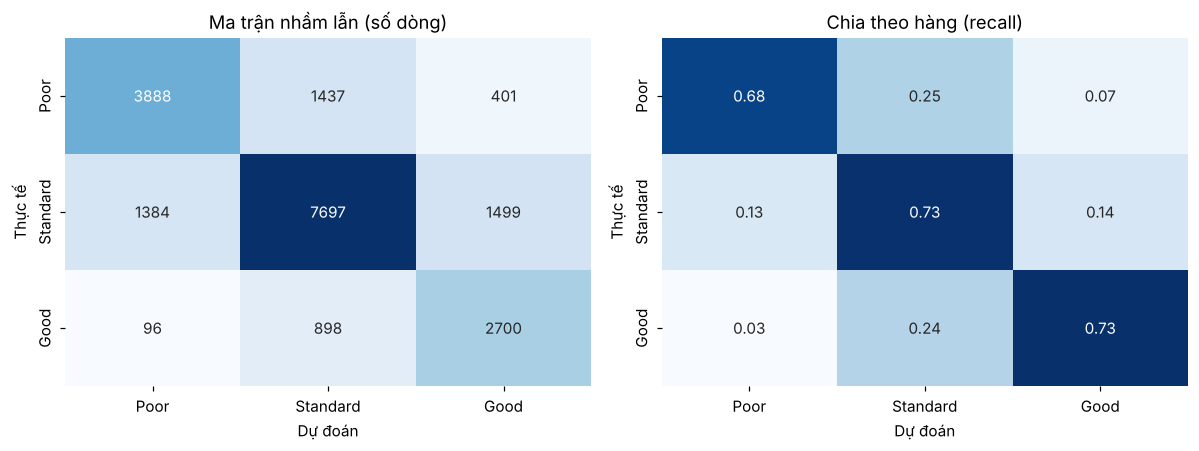

In [21]:
cm = confusion_matrix(y_test, pred, labels=LABELS)
fig, ax = plt.subplots(1, 2, figsize=(11, 4.2))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=LABELS, yticklabels=LABELS, ax=ax[0], cbar=False)
ax[0].set_title('Ma trận nhầm lẫn (số dòng)')
sns.heatmap(cm / cm.sum(axis=1, keepdims=True), annot=True, fmt='.2f', cmap='Blues',
            xticklabels=LABELS, yticklabels=LABELS, ax=ax[1], cbar=False)
ax[1].set_title('Chia theo hàng (recall)')
for a in ax:
    a.set_xlabel('Dự đoán')
    a.set_ylabel('Thực tế')
plt.tight_layout()
plt.show()

In [22]:
def fit_and_score(make_model, X_fit, X_eval):
    p = make_model().fit(X_fit, y_train).predict(X_eval)
    return {'accuracy': accuracy_score(y_test, p), 'macro-F1': f1_score(y_test, p, average='macro')}

def split_stage(stage):
    m = stage_full[stage]
    return m.iloc[train_idx], m.iloc[test_idx]

LR, HGB_MODEL = MODELS['Logistic Regression'], MODELS[HGB]
rows = {'Đoán lớp phổ biến': fit_and_score(CANDIDATES['Dummy (lớp phổ biến)'], X_train, X_test)}
rows['Logistic Regression – dữ liệu THÔ (S0, đặc trưng gốc)'] = fit_and_score(LR, *split_stage(STAGE_NAMES[0]))
rows['Logistic Regression – dữ liệu SẠCH, đặc trưng gốc (S3)'] = fit_and_score(LR, *split_stage(STAGE_NAMES[3]))
rows['HistGradientBoosting – dữ liệu THÔ (S0, đặc trưng gốc)'] = fit_and_score(HGB_MODEL, *split_stage(STAGE_NAMES[0]))
rows['HistGradientBoosting – dữ liệu SẠCH, đặc trưng gốc (S3)'] = fit_and_score(HGB_MODEL, *split_stage(STAGE_NAMES[3]))
rows[f'{best_name}, dữ liệu sạch + đặc trưng nhân quả (MÔ HÌNH CUỐI)'] = {'accuracy': acc, 'macro-F1': macro_f1}

final_comparison = pd.DataFrame(rows).T
final_comparison.index.name = 'mô hình / dữ liệu'
final_comparison.round(4)

,accuracy,macro-F1
mô hình / dữ liệu,,
Đoán lớp phổ biến,0.5290,0.2307
"Logistic Regression – dữ liệu THÔ (S0, đặc trưng gốc)",0.6169,0.5868
"Logistic Regression – dữ liệu SẠCH, đặc trưng gốc (S3)",0.6627,0.6434
"HistGradientBoosting – dữ liệu THÔ (S0, đặc trưng gốc)",0.6998,0.6778
"HistGradientBoosting – dữ liệu SẠCH, đặc trưng gốc (S3)",0.7045,0.6832
"Random Forest (tuned), dữ liệu sạch + đặc trưng nhân quả (MÔ HÌNH CUỐI)",0.7143,0.6996


In [23]:
def as_plain(value):
    """Đổi số numpy sang số Python để ghi JSON."""
    if isinstance(value, np.floating):
        return float(value)
    if isinstance(value, np.integer):
        return int(value)
    return value

metrics = {'model': best_name, 'params': {k: as_plain(v) for k, v in best_params.items()}, 'class_weight': CLASS_WEIGHT,
           'accuracy': acc, 'macro_f1': macro_f1, 'roc_auc_ovr': auc, 'log_loss': logloss,
           'accuracy_ci95': [float(np.percentile(boot_acc, 2.5)), float(np.percentile(boot_acc, 97.5))],
           'macro_f1_ci95': [float(np.percentile(boot_f1, 2.5)), float(np.percentile(boot_f1, 97.5))],
           'n_test_rows': int(len(y_test)), 'n_test_customers': int(cust_test.nunique())}
with open('../data/reports/final_test_metrics.json', 'w') as f:
    json.dump(metrics, f, ensure_ascii=False, indent=1)
final_comparison.to_csv('../data/reports/final_test_comparison.csv')

baseline_acc = float((y_test == 'Standard').mean())
say(f"""**Kết quả cuối (2.500 khách giữ kín):** accuracy {acc:.3f} (khoảng tin cậy 95% {interval(boot_acc)}), macro-F1 {macro_f1:.3f} (khoảng tin cậy 95% {interval(boot_f1)}), trong khi luôn đoán Standard chỉ cho accuracy {baseline_acc:.3f}.""")

**Kết quả cuối (2.500 khách giữ kín):** accuracy 0,714 (khoảng tin cậy 95% 0,702 đến 0,726), macro-F1 0,700 (khoảng tin cậy 95% 0,685 đến 0,711), trong khi luôn đoán Standard chỉ cho accuracy 0,529.

## 4.8 Mô hình dựa vào đặc trưng nào?
Dùng permutation importance: xáo trộn giá trị của một đặc trưng trên tập kiểm tra rồi xem macro-F1 giảm bao nhiêu. Cách này tin cậy hơn độ quan trọng có sẵn trong mô hình cây vì đo trên dữ liệu chưa thấy. Ngoài từng cột, ta còn xáo trộn cả nhóm đặc trưng một lúc để thấy nhóm nào của pipeline mang giá trị.

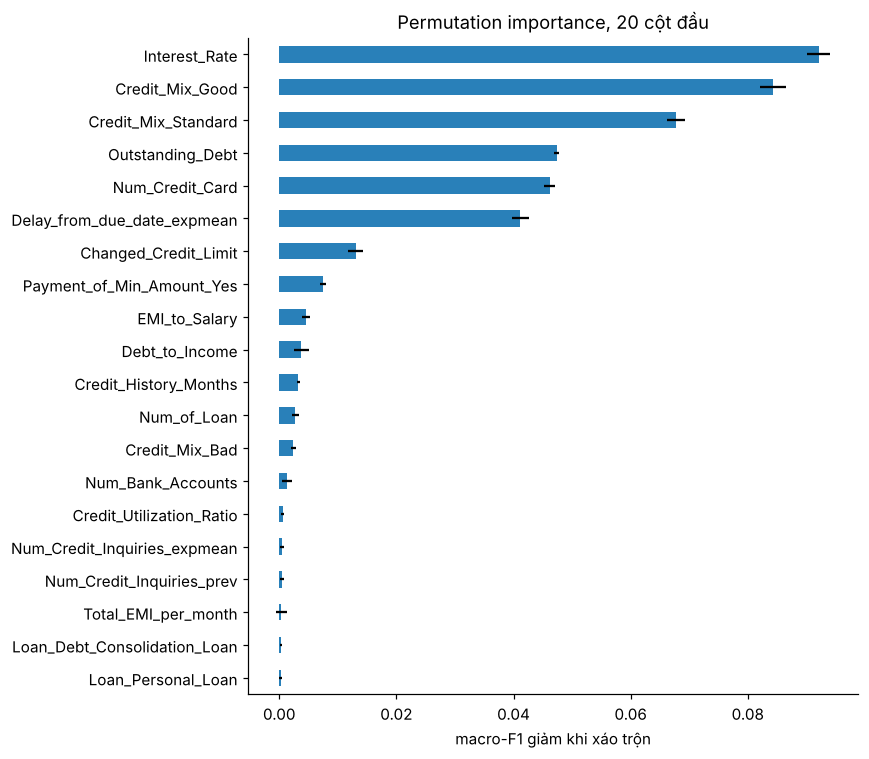

,mean,sd
Interest_Rate,0.0921,0.0020
Credit_Mix_Good,0.0843,0.0022
Credit_Mix_Standard,0.0678,0.0016
Outstanding_Debt,0.0474,0.0004
Num_Credit_Card,0.0462,0.0009
Delay_from_due_date_expmean,0.0412,0.0014
Changed_Credit_Limit,0.0130,0.0013
Payment_of_Min_Amount_Yes,0.0075,0.0005
EMI_to_Salary,0.0045,0.0007
Debt_to_Income,0.0038,0.0013


In [24]:
def macro_f1_score(estimator, X, y):
    return f1_score(y, estimator.predict(X), average='macro')

sample = np.random.default_rng(1).choice(len(X_test), size=min(12000, len(X_test)), replace=False)
perm = permutation_importance(final, X_test.iloc[sample], y_test.iloc[sample], scoring=macro_f1_score,
                              n_repeats=3, random_state=0, n_jobs=1)
importance = pd.DataFrame({'mean': perm.importances_mean, 'sd': perm.importances_std},
                          index=X_test.columns).sort_values('mean', ascending=False)

fig, ax = plt.subplots(figsize=(8, 7))
top20 = importance.head(20)[::-1]
top20['mean'].plot(kind='barh', xerr=top20['sd'], ax=ax, color='#2980b9')
ax.set_xlabel('macro-F1 giảm khi xáo trộn')
ax.set_title('Permutation importance, 20 cột đầu')
plt.tight_layout()
plt.show()
importance.head(12).round(4)

In [25]:
def group_of_column(col):
    for group, features in cf.FEATURE_GROUPS.items():
        for f in features:
            if col == f or (f in cf.CATEGORICAL and col.startswith(f + '_')):
                return group
    return '?'

column_group = pd.Series({c: group_of_column(c) for c in X_test.columns})
assert (column_group != '?').all()

rng = np.random.default_rng(2)
X_s = X_test.iloc[sample].reset_index(drop=True)
y_s = y_test.iloc[sample].reset_index(drop=True)
base_f1 = f1_score(y_s, final.predict(X_s), average='macro')

rows = []
for group in ['BASE', 'RATIO', 'LOAN', 'PB_SPLIT', 'LAG']:
    cols = list(column_group.index[column_group == group])
    drops = []
    for _ in range(3):
        X_shuffled = X_s.copy()
        X_shuffled[cols] = X_s[cols].values[rng.permutation(len(X_s))]
        drops.append(base_f1 - f1_score(y_s, final.predict(X_shuffled), average='macro'))
    rows.append({'nhóm': group, 'số cột': len(cols), 'macro-F1 giảm khi xáo trộn cả nhóm': np.mean(drops)})
group_importance = pd.DataFrame(rows).set_index('nhóm')
group_importance.round(4)

,số cột,macro-F1 giảm khi xáo trộn cả nhóm
nhóm,,
BASE,45,0.3544
RATIO,7,0.0065
LOAN,9,-0.0005
PB_SPLIT,7,-0.0003
LAG,12,0.0437


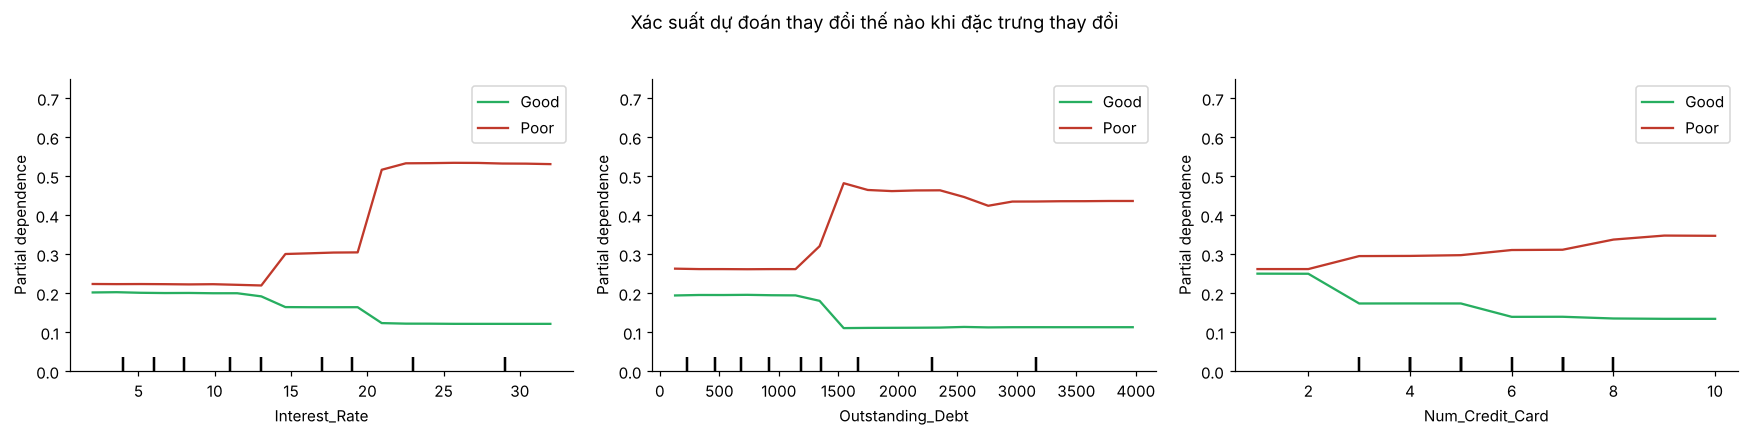

In [26]:
dummy_prefix = tuple(c + '_' for c in cf.CATEGORICAL)
top3 = [c for c in importance.index if not c.startswith(dummy_prefix)][:3]

fig, ax = plt.subplots(1, 3, figsize=(16, 3.8))
for target in ['Good', 'Poor']:
    PartialDependenceDisplay.from_estimator(final, X_test.iloc[sample[:3000]], top3, target=target, ax=ax,
                                            method='brute', response_method='predict_proba',
                                            line_kw={'color': COLORS[target], 'label': target}, grid_resolution=20)
for a in ax:
    a.set_ylim(0, 0.75)
ax[0].legend()
plt.suptitle('Xác suất dự đoán thay đổi thế nào khi đặc trưng thay đổi', y=1.03)
plt.tight_layout()
plt.show()

In [27]:
top_text = ', '.join(f'`{c}` ({v:.3f})' for c, v in importance['mean'].head(6).items())
drop = group_importance['macro-F1 giảm khi xáo trộn cả nhóm']
small_groups = [k for k in drop.index if drop[k] < 0.01]

say(f"""**Đọc kết quả**

- 6 đặc trưng quan trọng nhất (macro-F1 giảm khi xáo trộn): {top_text}. Đều là chỉ số về nợ, thanh toán và hạng mục tín dụng, hợp lý về mặt tài chính và khớp với các cột có hiệu ứng lớn ở EDA (mục 1.7). Cột `Month_Num` hay `Occupation` không nằm đầu danh sách. Cột one-hot bị xáo trộn riêng từng cột, nên độ quan trọng của `Credit_Mix` nói chung lớn hơn con số của từng cột `Credit_Mix_*`.
- Theo nhóm, `BASE` (cột gốc đã sạch) giữ gần hết tín hiệu (giảm {drop['BASE']:.3f}), `LAG` giảm {drop['LAG']:.3f}, các nhóm {', '.join('`' + k + '`' for k in small_groups)} giảm dưới 0,01. Điều này khớp với ablation ở mục 4.3: đặc trưng tự tạo không thêm nhiều thông tin so với cột gốc. `LAG` làm điểm giảm khi xáo trộn nhưng bỏ đi gần như không ảnh hưởng, có thể vì các cột gốc tương quan cao với nó đã thay được.
- PDP vẽ xác suất dự đoán của lớp Good và Poor theo từng đặc trưng số hàng đầu. Nhìn hướng của đường cong để xem mô hình có hợp lý về tài chính không, ví dụ lãi suất cao thì xác suất Poor tăng và Good giảm.""")

**Đọc kết quả**

- 6 đặc trưng quan trọng nhất (macro-F1 giảm khi xáo trộn): `Interest_Rate` (0,092), `Credit_Mix_Good` (0,084), `Credit_Mix_Standard` (0,068), `Outstanding_Debt` (0,047), `Num_Credit_Card` (0,046), `Delay_from_due_date_expmean` (0,041). Đều là chỉ số về nợ, thanh toán và hạng mục tín dụng, hợp lý về mặt tài chính và khớp với các cột có hiệu ứng lớn ở EDA (mục 1.7). Cột `Month_Num` hay `Occupation` không nằm đầu danh sách. Cột one-hot bị xáo trộn riêng từng cột, nên độ quan trọng của `Credit_Mix` nói chung lớn hơn con số của từng cột `Credit_Mix_*`.
- Theo nhóm, `BASE` (cột gốc đã sạch) giữ gần hết tín hiệu (giảm 0,354), `LAG` giảm 0,044, các nhóm `RATIO`, `LOAN`, `PB_SPLIT` giảm dưới 0,01. Điều này khớp với ablation ở mục 4.3: đặc trưng tự tạo không thêm nhiều thông tin so với cột gốc. `LAG` làm điểm giảm khi xáo trộn nhưng bỏ đi gần như không ảnh hưởng, có thể vì các cột gốc tương quan cao với nó đã thay được.
- PDP vẽ xác suất dự đoán của lớp Good và Poor theo từng đặc trưng số hàng đầu. Nhìn hướng của đường cong để xem mô hình có hợp lý về tài chính không, ví dụ lãi suất cao thì xác suất Poor tăng và Good giảm.

## 4.9 Phân tích lỗi: mô hình sai ở đâu?
Mô hình có thể đúng nhiều nhưng sai có hệ thống ở một số nhóm. Ta xem theo:
- tháng,
- mức `Credit_Mix`,
- dòng mà nhãn vừa đổi so với tháng trước (các điểm chuyển nhãn).

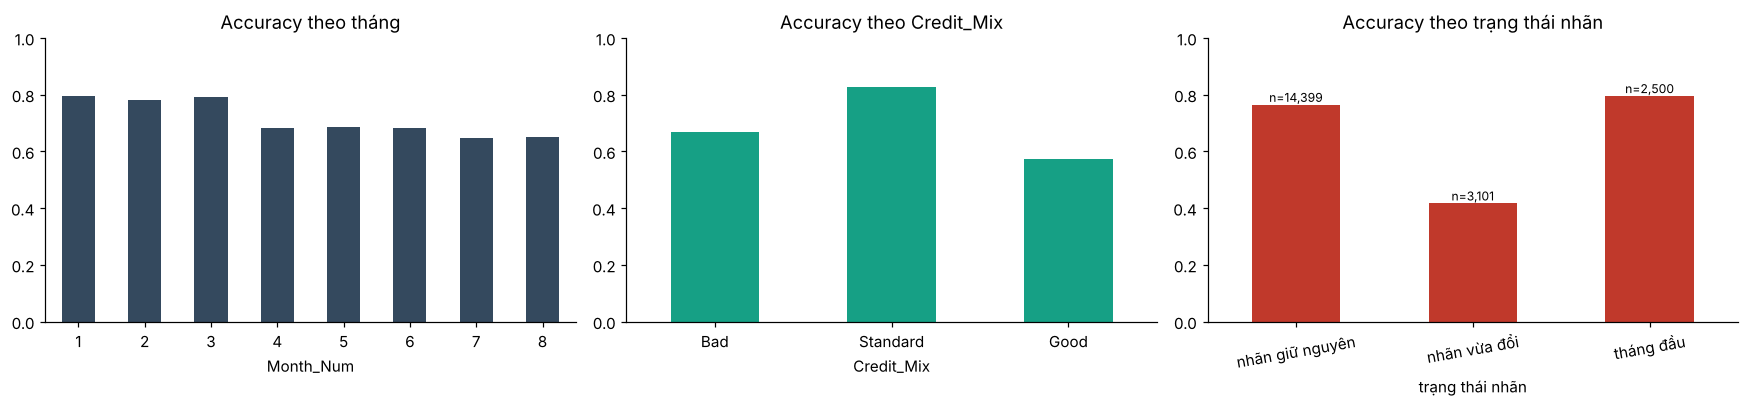

,mean,size
trạng thái nhãn,,
nhãn giữ nguyên,0.764,14399
nhãn vừa đổi,0.417,3101
tháng đầu,0.795,2500


In [28]:
test_rows = clean.iloc[test_idx].reset_index(drop=True).assign(pred=pred, correct=(pred == y_test.values))
test_rows['prev_label'] = test_rows.groupby('Customer_ID')['Credit_Score'].shift(1)
test_rows['trạng thái nhãn'] = np.where(test_rows.prev_label.isna(), 'tháng đầu',
                                        np.where(test_rows.prev_label == test_rows.Credit_Score, 'nhãn giữ nguyên', 'nhãn vừa đổi'))

fig, ax = plt.subplots(1, 3, figsize=(16, 3.8))
test_rows.groupby('Month_Num').correct.mean().plot(kind='bar', ax=ax[0], color='#34495e', rot=0)
ax[0].set_title('Accuracy theo tháng')
test_rows.groupby('Credit_Mix').correct.mean().reindex(['Bad', 'Standard', 'Good']).plot(kind='bar', ax=ax[1], color='#16a085', rot=0)
ax[1].set_title('Accuracy theo Credit_Mix')
by_state = test_rows.groupby('trạng thái nhãn').correct.agg(['mean', 'size'])
by_state['mean'].plot(kind='bar', ax=ax[2], color='#c0392b', rot=10)
ax[2].set_title('Accuracy theo trạng thái nhãn')
for i, (m, n) in enumerate(zip(by_state['mean'], by_state['size'])):
    ax[2].text(i, m, f'n={n:,}', ha='center', va='bottom', fontsize=8)
for a in ax:
    a.set_ylim(0, 1)
plt.tight_layout()
plt.show()
by_state.round(3)

In [29]:
with_prev = clean.assign(prev=clean.groupby('Customer_ID')['Credit_Score'].shift(1))
change_rate = (with_prev.prev.notna() & (with_prev.prev != with_prev.Credit_Score)).groupby(with_prev.Month_Num).mean()

by_month = test_rows.groupby('Month_Num').correct.agg(['mean', 'size'])
by_month.columns = ['accuracy (tập kiểm tra)', 'số dòng']
by_month['tỷ lệ nhãn đổi so với tháng trước (toàn bộ dữ liệu)'] = change_rate.round(3)
display(by_month.round(3).T)

by_mix = test_rows.groupby('Credit_Mix').correct.agg(['mean', 'size']).reindex(['Bad', 'Standard', 'Good'])
by_mix.columns = ['accuracy', 'số dòng']
display(by_mix.round(3).T)

Month_Num,1,2,3,4,5,6,7,8
accuracy (tập kiểm tra),0.795,0.780,0.792,0.684,0.685,0.683,0.646,0.649
số dòng,2500.000,2500.000,2500.000,2500.000,2500.000,2500.000,2500.000,2500.000
tỷ lệ nhãn đổi so với tháng trước (toàn bộ dữ liệu),0.000,0.129,0.131,0.256,0.146,0.143,0.273,0.145


Credit_Mix,Bad,Standard,Good
accuracy,0.67,0.828,0.571
số dòng,4744.00,9320.000,5936.000


In [30]:
good_by_month = pd.DataFrame({'Good dự đoán': (test_rows.pred == 'Good').groupby(test_rows.Month_Num).mean(),
                              'Good thật': (test_rows.Credit_Score == 'Good').groupby(test_rows.Month_Num).mean()})
display(good_by_month.round(3).T)

Month_Num,1,2,3,4,5,6,7,8
Good dự đoán,0.222,0.223,0.228,0.230,0.233,0.235,0.235,0.234
Good thật,0.163,0.162,0.168,0.197,0.186,0.190,0.203,0.208


In [31]:
test_rows['conf'] = proba.max(axis=1)
bins = pd.cut(test_rows['conf'], [0, .5, .6, .7, .8, .9, 1.0])
test_rows.groupby(bins, observed=True).agg(n=('correct', 'size'), accuracy=('correct', 'mean'),
                                           độ_tin_cậy_TB=('conf', 'mean')).round(3)

,n,accuracy,độ_tin_cậy_TB
conf,,,
"(0.0, 0.5]",2968,0.477,0.468
"(0.5, 0.6]",3570,0.546,0.541
"(0.6, 0.7]",1772,0.675,0.647
"(0.7, 0.8]",4320,0.769,0.760
"(0.8, 0.9]",5850,0.852,0.858
"(0.9, 1.0]",1520,0.934,0.913


In [32]:
wrong_pairs = (test_rows[~test_rows.correct].groupby(['Credit_Score', 'pred']).size()
               .rename('số dòng sai').reset_index().sort_values('số dòng sai', ascending=False))
wrong_pairs['% tổng lỗi'] = (wrong_pairs['số dòng sai'] / (~test_rows.correct).sum() * 100).round(1)
wrong_pairs.rename(columns={'Credit_Score': 'thực tế', 'pred': 'dự đoán'})

,thực tế,dự đoán,số dòng sai,% tổng lỗi
4,Standard,Good,1499,26.2
3,Poor,Standard,1437,25.1
5,Standard,Poor,1384,24.2
1,Good,Standard,898,15.7
2,Poor,Good,401,7.0
0,Good,Poor,96,1.7


In [33]:
before_fill = cc.mark_invalid(cc.strip_numeric_text(cc.mark_placeholders(cc.add_month_num(raw))))
n_fixed = before_fill.drop(columns=['Type_of_Loan', 'Credit_Score']).isna().sum(axis=1).values[test_idx]
test_rows['số ô phải sửa'] = pd.cut(n_fixed, [-1, 0, 1, 2, 99], labels=['0', '1', '2', '≥3'])
test_rows['Monthly_Balance bị điền'] = before_fill['Monthly_Balance'].isna().values[test_idx]

by_fixed = (test_rows.groupby('số ô phải sửa', observed=True).correct.agg(['mean', 'size']).round(3)
            .rename(columns={'mean': 'accuracy', 'size': 'số dòng'}))
by_balance = (test_rows.groupby('Monthly_Balance bị điền').correct.agg(['mean', 'size']).round(3)
              .rename(columns={'mean': 'accuracy', 'size': 'số dòng'}))
display(by_fixed)
display(by_balance)

,accuracy,số dòng
số ô phải sửa,,
0,0.720,5865
1,0.715,7661
2,0.712,4515
≥3,0.699,1959


,accuracy,số dòng
Monthly_Balance bị điền,,
False,0.714,19772
True,0.702,228


In [34]:
poor_good_share = wrong_pairs[wrong_pairs.Credit_Score.isin(['Poor', 'Good']) & wrong_pairs.pred.isin(['Poor', 'Good'])]['% tổng lỗi'].sum()
acc_by_state = test_rows.groupby('trạng thái nhãn').correct.mean()
error_share = test_rows[~test_rows.correct]['trạng thái nhãn'].value_counts(normalize=True)
acc_by_month = test_rows.groupby('Month_Num').correct.mean()
others = change_rate.loc[[2, 3, 5, 6, 8]]

say(f"""**Phát hiện từ phân tích lỗi**

- Ở các dòng nhãn giữ nguyên so với tháng trước, accuracy là {acc_by_state['nhãn giữ nguyên']:.3f}. Ở các dòng nhãn vừa đổi chỉ còn {acc_by_state['nhãn vừa đổi']:.3f}. Nhóm nhãn vừa đổi chiếm {error_share['nhãn vừa đổi']:.0%} số lỗi dù là phần nhỏ của dữ liệu. Mô hình khó bắt đúng thời điểm nhãn chuyển.
- Theo tháng: accuracy là {test_rows[test_rows.Month_Num <= 3].correct.mean():.3f} ở tháng 1 đến 3 nhưng chỉ {test_rows[test_rows.Month_Num >= 4].correct.mean():.3f} ở tháng 4 đến 8 (thấp nhất {acc_by_month.min():.3f} ở tháng {int(acc_by_month.idxmin())}, cao nhất {acc_by_month.max():.3f} ở tháng {int(acc_by_month.idxmax())}). Tỷ lệ nhãn đổi so với tháng trước tăng lên {change_rate.loc[4]:.0%} ở tháng 4 và {change_rate.loc[7]:.0%} ở tháng 7, so với {others.min():.0%} đến {others.max():.0%} ở các tháng còn lại. Điều này khớp với việc accuracy tụt ở tháng 4 và 7, nhưng không giải thích hết, vì tháng 5, 6, 8 cũng thấp hơn tháng 2 và 3 dù tỷ lệ nhãn đổi tương đương. Phần còn lại mình chưa xác định được nguyên nhân. Có thể do cách dữ liệu tổng hợp được tạo ra (phân phối nhãn cũng dịch từ tháng 4: Good từ khoảng 16% lên khoảng 19%, Standard từ khoảng 56% xuống khoảng 52%).
- Theo số ô phải sửa trong dòng: accuracy {by_fixed['accuracy'].iloc[0]:.3f} ở dòng không phải sửa ô nào, {by_fixed['accuracy'].iloc[-1]:.3f} ở dòng có từ 3 ô. Riêng các dòng phải điền `Monthly_Balance`: {by_balance['accuracy'].get(True, float('nan')):.3f}, so với {by_balance['accuracy'].get(False, float('nan')):.3f} ở các dòng còn nguyên. Hai chênh lệch này có đáng kể không sẽ được kiểm tra ở phần kết luận.
- Nhầm trực tiếp Poor với Good chỉ chiếm {poor_good_share:.1f}% số lỗi. {100 - poor_good_share:.1f}% còn lại là nhầm với lớp giữa Standard, nơi ranh giới giữa các mức mờ nhất.""")

**Phát hiện từ phân tích lỗi**

- Ở các dòng nhãn giữ nguyên so với tháng trước, accuracy là 0,764. Ở các dòng nhãn vừa đổi chỉ còn 0,417. Nhóm nhãn vừa đổi chiếm 32% số lỗi dù là phần nhỏ của dữ liệu. Mô hình khó bắt đúng thời điểm nhãn chuyển.
- Theo tháng: accuracy là 0,789 ở tháng 1 đến 3 nhưng chỉ 0,670 ở tháng 4 đến 8 (thấp nhất 0,646 ở tháng 7, cao nhất 0,795 ở tháng 1). Tỷ lệ nhãn đổi so với tháng trước tăng lên 26% ở tháng 4 và 27% ở tháng 7, so với 13% đến 15% ở các tháng còn lại. Điều này khớp với việc accuracy tụt ở tháng 4 và 7, nhưng không giải thích hết, vì tháng 5, 6, 8 cũng thấp hơn tháng 2 và 3 dù tỷ lệ nhãn đổi tương đương. Phần còn lại mình chưa xác định được nguyên nhân. Có thể do cách dữ liệu tổng hợp được tạo ra (phân phối nhãn cũng dịch từ tháng 4: Good từ khoảng 16% lên khoảng 19%, Standard từ khoảng 56% xuống khoảng 52%).
- Theo số ô phải sửa trong dòng: accuracy 0,720 ở dòng không phải sửa ô nào, 0,699 ở dòng có từ 3 ô. Riêng các dòng phải điền `Monthly_Balance`: 0,702, so với 0,714 ở các dòng còn nguyên. Hai chênh lệch này có đáng kể không sẽ được kiểm tra ở phần kết luận.
- Nhầm trực tiếp Poor với Good chỉ chiếm 8,7% số lỗi. 91,3% còn lại là nhầm với lớp giữa Standard, nơi ranh giới giữa các mức mờ nhất.

## 4.10 Mức trần "nhìn lại": nếu có đủ 8 tháng
Bộ chính (nhân quả) là con số dùng được thật. Để biết thông tin của cả 8 tháng giúp thêm được bao nhiêu, ta đánh giá bộ có thêm `CUST_AGG` trên cùng tập kiểm tra. Kết quả này chỉ để tham khảo, không dùng làm kết quả chính.

In [35]:
X_retro = cf.make_matrix(feat, MAIN_GROUPS + ['CUST_AGG'])
retro_model = make_best(class_weight=CLASS_WEIGHT).fit(X_retro.iloc[train_idx], y_train)
retro_pred = retro_model.predict(X_retro.iloc[test_idx])
acc_retro = accuracy_score(y_test, retro_pred)
f1_retro = f1_score(y_test, retro_pred, average='macro')

say(f"""| Bộ đặc trưng | accuracy | macro-F1 |
|---|---|---|
| Nhân quả (kết quả chính) | {acc:.3f} | {macro_f1:.3f} |
| Nhìn lại 8 tháng (thêm CUST_AGG, mức trần tham khảo) | {acc_retro:.3f} | {f1_retro:.3f} |""")

| Bộ đặc trưng | accuracy | macro-F1 |
|---|---|---|
| Nhân quả (kết quả chính) | 0,714 | 0,700 |
| Nhìn lại 8 tháng (thêm CUST_AGG, mức trần tham khảo) | 0,716 | 0,702 |

In [36]:
fc = final_comparison['macro-F1']
LR_RAW, LR_CLEAN = 'Logistic Regression – dữ liệu THÔ (S0, đặc trưng gốc)', 'Logistic Regression – dữ liệu SẠCH, đặc trưng gốc (S3)'
HGB_RAW, HGB_CLEAN = 'HistGradientBoosting – dữ liệu THÔ (S0, đặc trưng gốc)', 'HistGradientBoosting – dữ liệu SẠCH, đặc trưng gốc (S3)'
test_gain_lr = fc[LR_CLEAN] - fc[LR_RAW]
test_gain_hgb = fc[HGB_CLEAN] - fc[HGB_RAW]
tuning_gain = macro_f1 - fc[HGB_CLEAN]

changed_rows = int((test_rows['trạng thái nhãn'] == 'nhãn vừa đổi').sum())
rows_with_prev = int((test_rows['trạng thái nhãn'] != 'tháng đầu').sum())

n_balance = int(test_rows['Monthly_Balance bị điền'].sum())
acc_balance_rest = float(test_rows.loc[~test_rows['Monthly_Balance bị điền'], 'correct'].mean())
se_balance = (acc_balance_rest * (1 - acc_balance_rest) / max(n_balance, 1)) ** 0.5
gap_balance = float(test_rows.loc[test_rows['Monthly_Balance bị điền'], 'correct'].mean()) - acc_balance_rest
p_none, p_many = by_fixed['accuracy'].iloc[0], by_fixed['accuracy'].iloc[-1]
n_none, n_many = by_fixed['số dòng'].iloc[0], by_fixed['số dòng'].iloc[-1]
gap_fixed = p_many - p_none
z_fixed = gap_fixed / ((p_none * (1 - p_none) / n_none + p_many * (1 - p_many) / n_many) ** 0.5)

def cv_pair(model_name):
    return (paired.loc[(model_name, 'S3 − S0'), 'Δ macro-F1 TB (điểm %)'], paired.loc[(model_name, 'S3 − S0'), 'số phần cải thiện'])

(lr_pts, lr_folds), (rf_pts, rf_folds), (hgb_pts, hgb_folds) = cv_pair('Logistic Regression'), cv_pair('Random Forest'), cv_pair(HGB)

say(f"""## Kết luận

**1. Làm sạch có giá trị đo được, nhưng lớn nhỏ tùy mô hình.** Cùng đặc trưng, cùng mô hình, đi từ dữ liệu thô (S0) đến làm sạch đầy đủ (S3), macro-F1 trong CV tăng {lr_pts:+.1f} điểm % ở Logistic Regression ({lr_folds} phần CV cải thiện), {rf_pts:+.1f} ở Random Forest ({rf_folds}) và {hgb_pts:+.1f} ở HistGradientBoosting ({hgb_folds}). Trên tập kiểm tra giữ kín mức tăng là {test_gain_lr * 100:+.1f} điểm % (Logistic Regression) và {test_gain_hgb * 100:+.1f} điểm % (HistGradientBoosting). Mô hình tuyến tính được lợi nhiều nhất vì bị giá trị cực lớn phá hỏng, còn mô hình cây vốn chịu được ngoại lệ nên lợi ít hơn.

**2. Phải làm sạch có hiểu biết, không phải máy móc.** Ở mô hình cây, chỉ bỏ giá trị giả hay giá trị vô lý rồi điền trung vị chung (S1, S2) không hơn dữ liệu thô. Để mô hình tự xử lý NaN (S2*) cũng không giúp. Lợi ích chỉ xuất hiện khi điền theo từng khách và theo ràng buộc giữa các cột (S3 hơn S2* {star_gap:+.1f} điểm %).

**3. Kết quả cuối** (2.500 khách giữ kín, chưa từng dùng để chọn gì): accuracy {acc:.3f} (khoảng tin cậy 95% {interval(boot_acc)}), macro-F1 {macro_f1:.3f} (khoảng tin cậy 95% {interval(boot_f1)}), ROC-AUC {auc:.3f}. Luôn đoán Standard cho accuracy {baseline_acc:.3f}. So với HistGradientBoosting mặc định trên dữ liệu thô, mô hình cuối cao hơn {(macro_f1 - fc[HGB_RAW]) * 100:+.1f} điểm % macro-F1, trong đó {test_gain_hgb * 100:+.1f} điểm % nhờ làm sạch và {tuning_gain * 100:+.1f} điểm % nhờ chọn mô hình, chỉnh siêu tham số và thêm đặc trưng.

**4. Tạo đặc trưng chỉ là việc phụ.** Các nhóm đặc trưng tự tạo gần như không cải thiện mô hình (mục 4.3). Bộ "nhìn lại 8 tháng" chỉ hơn bộ nhân quả {(f1_retro - macro_f1) * 100:+.1f} điểm % macro-F1 trên tập kiểm tra (accuracy {acc_retro:.3f} so với {acc:.3f}).

**5. Mô hình sai ở đâu.**
- Ở các dòng nhãn vừa đổi so với tháng trước (chiếm {changed_rows / rows_with_prev:.0%} số dòng nhưng {error_share['nhãn vừa đổi']:.0%} số lỗi), accuracy chỉ {acc_by_state['nhãn vừa đổi']:.2f}, so với {acc_by_state['nhãn giữ nguyên']:.2f} khi nhãn giữ nguyên.
- Nhầm trực tiếp Poor với Good chỉ chiếm {poor_good_share:.1f}% số lỗi, phần còn lại là ranh giới với Standard.
- Dòng càng phải sửa nhiều ô thì accuracy càng giảm nhẹ ({p_none:.3f} ở dòng không sửa ô nào, {p_many:.3f} ở dòng từ 3 ô, chênh {gap_fixed * 100:+.1f} điểm %, z ≈ {z_fixed:.1f}). Chiều này hợp lý vì giá trị điền chỉ là ước lượng, nhưng mức giảm nhỏ và chưa đạt ý nghĩa thống kê (|z| < 2). Phép tính này còn coi các dòng là độc lập, trong khi 8 dòng của một khách giống nhau nên sai số thật còn lớn hơn. Vì vậy chỉ là gợi ý.
- Với {n_balance} dòng phải điền `Monthly_Balance`, chênh lệch {gap_balance * 100:+.1f} điểm % nằm trong sai số chuẩn khoảng {se_balance * 100:.1f} điểm %, nên chưa kết luận được là có ảnh hưởng.

### Hạn chế
- Đây là dữ liệu tổng hợp (Kaggle), nhãn có nhiều nhiễu theo tháng (mục 1.2). Ngay cả khi biết trước cả 8 tháng của khách, kết quả cũng tăng rất ít (mục 4.10), và các mô hình rất khác nhau (cây đơn, random forest, boosting) đều dừng quanh 0,70 đến 0,71 accuracy trong CV. Điều đáng tin ở bài này là chênh lệch giữa các giai đoạn làm sạch trong cùng điều kiện, không phải con số tuyệt đối. Không nên suy ra hiệu năng trên dữ liệu ngân hàng thật.
- Thí nghiệm che 10% để chọn cách điền giả định ô thiếu xuất hiện ngẫu nhiên. `Monthly_Balance` có dấu hiệu thiếu không ngẫu nhiên (notebook 3, mục 3.1) nên sai số thật ở nhóm đó không đo được. `Amount_invested_monthly` và `Monthly_Balance` là giá trị ước lượng.
- Việc làm sạch (trung vị toàn cục, mô hình điền thiếu) được tính trên cả 100.000 dòng, không dùng nhãn, trước khi chia train và test. Không rò rỉ nhãn, nhưng nếu triển khai thật thì các tham số này chỉ nên học từ dữ liệu huấn luyện.
- Chỉ chia train và test một lần (hạt ngẫu nhiên cố định). Khoảng tin cậy bootstrap phản ánh dao động do mẫu kiểm tra, không phản ánh dao động do cách chia.
- Chỉnh siêu tham số bằng tìm kiếm ngẫu nhiên (CV 3 phần, 20 và 8 cấu hình), chưa chỉnh tới cùng. Chưa dùng `test.csv` vì file này không có nhãn. Có thể áp dụng `clean()` và mô hình cuối để dự đoán cho nó.""")
print(f'Tổng thời gian chạy notebook: {(time.time() - start_time) / 60:.1f} phút')

## Kết luận

**1. Làm sạch có giá trị đo được, nhưng lớn nhỏ tùy mô hình.** Cùng đặc trưng, cùng mô hình, đi từ dữ liệu thô (S0) đến làm sạch đầy đủ (S3), macro-F1 trong CV tăng +5,1 điểm % ở Logistic Regression (5/5 phần CV cải thiện), +1,0 ở Random Forest (5/5) và +0,9 ở HistGradientBoosting (5/5). Trên tập kiểm tra giữ kín mức tăng là +5,7 điểm % (Logistic Regression) và +0,5 điểm % (HistGradientBoosting). Mô hình tuyến tính được lợi nhiều nhất vì bị giá trị cực lớn phá hỏng, còn mô hình cây vốn chịu được ngoại lệ nên lợi ít hơn.

**2. Phải làm sạch có hiểu biết, không phải máy móc.** Ở mô hình cây, chỉ bỏ giá trị giả hay giá trị vô lý rồi điền trung vị chung (S1, S2) không hơn dữ liệu thô. Để mô hình tự xử lý NaN (S2*) cũng không giúp. Lợi ích chỉ xuất hiện khi điền theo từng khách và theo ràng buộc giữa các cột (S3 hơn S2* +0,8 điểm %).

**3. Kết quả cuối** (2.500 khách giữ kín, chưa từng dùng để chọn gì): accuracy 0,714 (khoảng tin cậy 95% 0,702 đến 0,726), macro-F1 0,700 (khoảng tin cậy 95% 0,685 đến 0,711), ROC-AUC 0,861. Luôn đoán Standard cho accuracy 0,529. So với HistGradientBoosting mặc định trên dữ liệu thô, mô hình cuối cao hơn +2,2 điểm % macro-F1, trong đó +0,5 điểm % nhờ làm sạch và +1,6 điểm % nhờ chọn mô hình, chỉnh siêu tham số và thêm đặc trưng.

**4. Tạo đặc trưng chỉ là việc phụ.** Các nhóm đặc trưng tự tạo gần như không cải thiện mô hình (mục 4.3). Bộ "nhìn lại 8 tháng" chỉ hơn bộ nhân quả +0,3 điểm % macro-F1 trên tập kiểm tra (accuracy 0,716 so với 0,714).

**5. Mô hình sai ở đâu.**
- Ở các dòng nhãn vừa đổi so với tháng trước (chiếm 18% số dòng nhưng 32% số lỗi), accuracy chỉ 0,42, so với 0,76 khi nhãn giữ nguyên.
- Nhầm trực tiếp Poor với Good chỉ chiếm 8,7% số lỗi, phần còn lại là ranh giới với Standard.
- Dòng càng phải sửa nhiều ô thì accuracy càng giảm nhẹ (0,720 ở dòng không sửa ô nào, 0,699 ở dòng từ 3 ô, chênh -2,1 điểm %, z ≈ -1,8). Chiều này hợp lý vì giá trị điền chỉ là ước lượng, nhưng mức giảm nhỏ và chưa đạt ý nghĩa thống kê (|z| < 2). Phép tính này còn coi các dòng là độc lập, trong khi 8 dòng của một khách giống nhau nên sai số thật còn lớn hơn. Vì vậy chỉ là gợi ý.
- Với 228 dòng phải điền `Monthly_Balance`, chênh lệch -1,3 điểm % nằm trong sai số chuẩn khoảng 3,0 điểm %, nên chưa kết luận được là có ảnh hưởng.

### Hạn chế
- Đây là dữ liệu tổng hợp (Kaggle), nhãn có nhiều nhiễu theo tháng (mục 1.2). Ngay cả khi biết trước cả 8 tháng của khách, kết quả cũng tăng rất ít (mục 4.10), và các mô hình rất khác nhau (cây đơn, random forest, boosting) đều dừng quanh 0,70 đến 0,71 accuracy trong CV. Điều đáng tin ở bài này là chênh lệch giữa các giai đoạn làm sạch trong cùng điều kiện, không phải con số tuyệt đối. Không nên suy ra hiệu năng trên dữ liệu ngân hàng thật.
- Thí nghiệm che 10% để chọn cách điền giả định ô thiếu xuất hiện ngẫu nhiên. `Monthly_Balance` có dấu hiệu thiếu không ngẫu nhiên (notebook 3, mục 3.1) nên sai số thật ở nhóm đó không đo được. `Amount_invested_monthly` và `Monthly_Balance` là giá trị ước lượng.
- Việc làm sạch (trung vị toàn cục, mô hình điền thiếu) được tính trên cả 100,000 dòng, không dùng nhãn, trước khi chia train và test. Không rò rỉ nhãn, nhưng nếu triển khai thật thì các tham số này chỉ nên học từ dữ liệu huấn luyện.
- Chỉ chia train và test một lần (hạt ngẫu nhiên cố định). Khoảng tin cậy bootstrap phản ánh dao động do mẫu kiểm tra, không phản ánh dao động do cách chia.
- Chỉnh siêu tham số bằng tìm kiếm ngẫu nhiên (CV 3 phần, 20 và 8 cấu hình), chưa chỉnh tới cùng. Chưa dùng `test.csv` vì file này không có nhãn. Có thể áp dụng `clean()` và mô hình cuối để dự đoán cho nó.

Tổng thời gian chạy notebook: 58.7 phút
